Objective: To predict whether a customer will default on their credit card payment in the following month (default_payment_next_month), where 1 represents default and 0 represents non-default.

About Dataset

This dataset contains information on default payments, demographic factors, credit data, history of payment, and bill statements of credit card clients in Taiwan from April 2005 to September 2005.
Content

There are 25 variables:

    ID: ID of each client
    LIMIT_BAL: Amount of given credit in NT dollars (includes individual and family/supplementary credit
    SEX: Gender (1=male, 2=female)
    EDUCATION: (1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown)
    MARRIAGE: Marital status (1=married, 2=single, 3=others)
    AGE: Age in years
    PAY_0: Repayment status in September, 2005 (-1=pay duly, 1=payment delay for one month, 2=payment delay for two months, ... 8=payment delay for eight months, 9=payment delay for nine months and above)
    PAY_2: Repayment status in August, 2005 (scale same as above)
    PAY_3: Repayment status in July, 2005 (scale same as above)
    PAY_4: Repayment status in June, 2005 (scale same as above)
    PAY_5: Repayment status in May, 2005 (scale same as above)
    PAY_6: Repayment status in April, 2005 (scale same as above)
    BILL_AMT1: Amount of bill statement in September, 2005 (NT dollar)
    BILL_AMT2: Amount of bill statement in August, 2005 (NT dollar)
    BILL_AMT3: Amount of bill statement in July, 2005 (NT dollar)
    BILL_AMT4: Amount of bill statement in June, 2005 (NT dollar)
    BILL_AMT5: Amount of bill statement in May, 2005 (NT dollar)
    BILL_AMT6: Amount of bill statement in April, 2005 (NT dollar)
    PAY_AMT1: Amount of previous payment in September, 2005 (NT dollar)
    PAY_AMT2: Amount of previous payment in August, 2005 (NT dollar)
    PAY_AMT3: Amount of previous payment in July, 2005 (NT dollar)
    PAY_AMT4: Amount of previous payment in June, 2005 (NT dollar)
    PAY_AMT5: Amount of previous payment in May, 2005 (NT dollar)
    PAY_AMT6: Amount of previous payment in April, 2005 (NT dollar)
    default.payment.next.month: Default payment (1=yes, 0=no)



In [ ]:
# Importing the required packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving UCI_Credit_Card.csv to UCI_Credit_Card.csv


In [ ]:
import io
data = pd.read_csv(io.BytesIO(uploaded['UCI_Credit_Card.csv']))# Dataset is now stored in a Pandas Dataframe



# Data Description

In [ ]:
data.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [ ]:
data.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

In [ ]:
data.shape # 30,000 rows and 25 columns

(30000, 25)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
data.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [ ]:
data.isnull().sum() #checking for total null values - no null values found

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


In [ ]:
data.rename(columns={'default.payment.next.month':'default_payment_next_month'},inplace=True)

# Analysing the features and data cleaning (where ever required)

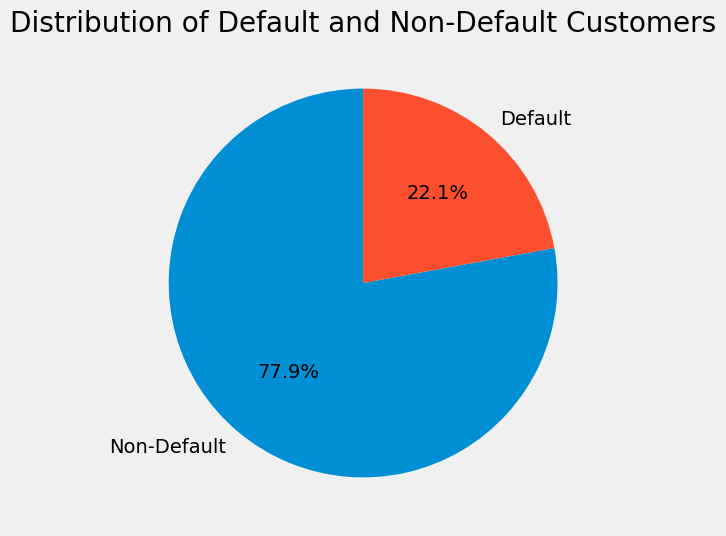

In [ ]:
# Count the two target classes
target_counts = data['default_payment_next_month'].value_counts()

# Pie chart
plt.figure(figsize=(6, 6))

plt.pie(
    target_counts,
    labels=['Non-Default', 'Default'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Default and Non-Default Customers')
plt.show()



In [ ]:
data.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default_payment_next_month'],
      dtype='object')

In [ ]:
data.drop('ID',axis = 1,inplace=True)


Dropped non-informative identifier column (ID)

Categorical Features : SEX,
Ordinal Features  EDUCATION, MARRIAGE, PAY_0 - 6
Continuous Features - LIMIT_BAL, AGE, BILL_AMT1 - 6,PAY_AMT1 - 6

Sex -> Categorical

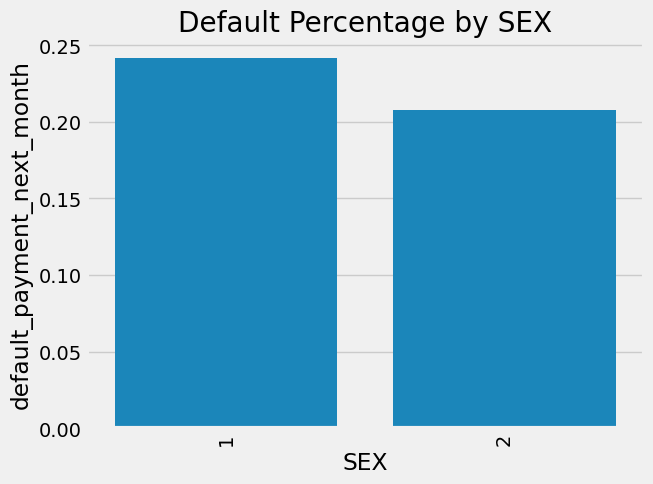

In [ ]:

sns.barplot(x="SEX",y="default_payment_next_month",data=data,ci=None)
plt.xticks(rotation=90)
plt.title('Default Percentage by SEX')
plt.show()

Male clients exhibit a higher default rate compared to female clients

EDUCATION -> ORDINAL

In [ ]:
pd.crosstab(data.EDUCATION,data.default_payment_next_month,margins=True).style.background_gradient(cmap='summer_r')

default_payment_next_month,0,1,All
EDUCATION,,,
0,14,0,14
1,8549,2036,10585
2,10700,3330,14030
3,3680,1237,4917
4,116,7,123
5,262,18,280
6,43,8,51
All,23364,6636,30000


In [ ]:
# Remove category 0
data = data[data['EDUCATION'] != 0]

# Combine categories 5 and 6 as 6
data['EDUCATION'] = data['EDUCATION'].replace({6: 5})

Text(0.5, 1.0, 'average default% as per education class')

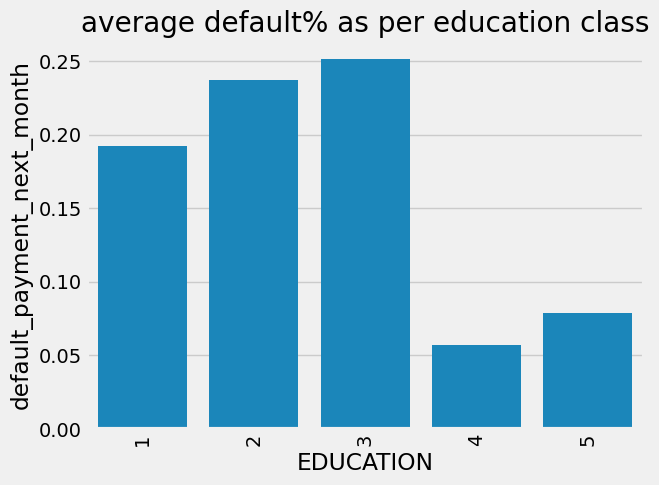

In [ ]:
sns.barplot(x="EDUCATION",y="default_payment_next_month",data=data,ci=None)
plt.xticks(rotation=90)
plt.title('average default% as per education class')

Category 0 was removed because it was not defined in the data description and contains only 14 observations. Therefore too small for reliable analysis.
Categories 6 was merged in 5 because both represent unspecified/unknown education levels.

Clients with High School education (Category 3) show the highest default rate among the cleaned education categories.


MARRIAGE-> ORDINAL


In [ ]:
pd.crosstab(data.MARRIAGE,data.default_payment_next_month,margins=True).style.background_gradient(cmap='summer_r')

default_payment_next_month,0,1,All
MARRIAGE,,,
0,49,5,54
1,10449,3206,13655
2,12613,3341,15954
3,239,84,323
All,23350,6636,29986


In [ ]:
indices2 = data[data['MARRIAGE'] == 0].index
indices2
data.drop(indices2,axis=0,inplace=True)

In [ ]:
data[data['MARRIAGE']==0].values.any()

np.False_

Text(0.5, 1.0, 'average default% as per marriage class')

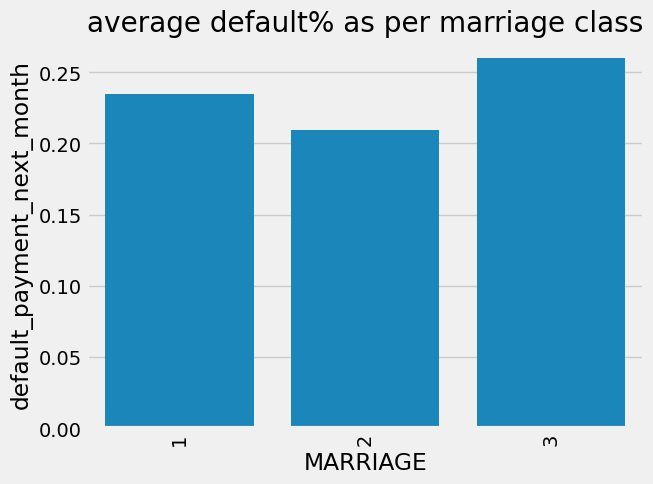

In [ ]:
sns.barplot(x="MARRIAGE",y="default_payment_next_month",data=data,ci=None)
plt.xticks(rotation=90)
plt.title('average default% as per marriage class')

Marriage Category 3 (“Other”) exhibits the highest default rate. Although Category 3 represents a very small proportion of the dataset, it may still be relevant in our evaluation due to its high default rate.

Category 0 was removed because it was not defined in the data description and it contains only 54 observations. It is therefore too small for reliable analysis.



In [ ]:
# Final row count
data.shape

(29932, 24)

The dataset contains monthly observations for repayment, billing, and payment variables. For the baseline analysis, I focus on the most recent observation from each group—PAY_0, BILL_AMT1, and PAY_AMT1—as these provide a snapshot of the customer's current repayment and financial behavior.

PAY_0 -> Ordinal

In [ ]:
pd.crosstab(data.PAY_0,data.default_payment_next_month,margins=True).style.background_gradient(cmap='summer_r')

default_payment_next_month,0,1,All
PAY_0,,,
-2,2385,364,2749
-1,4713,954,5667
0,12827,1886,14713
1,2427,1251,3678
2,820,1843,2663
3,78,244,322
4,24,52,76
5,12,13,25
6,5,6,11


Text(0.5, 1.0, 'average default% as per PAY_0 class')

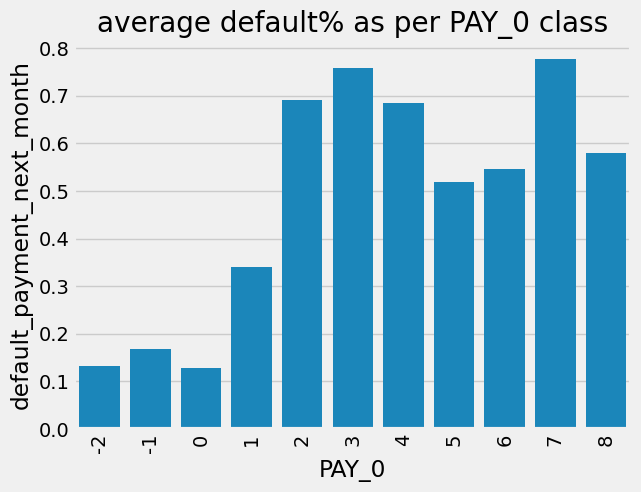

In [ ]:
sns.barplot(x="PAY_0",y="default_payment_next_month",data=data,ci=None)
plt.xticks(rotation=90)
plt.title('average default% as per PAY_0 class')


Category 0 is substantial, with approximately 14.7k records (almost 50% of the data), so it cannot be treated as an anomalous or negligible category. Although its exact meaning is not clearly defined in the dataset documentation, it may represent a valid repayment status that was not documented.

Category -2 is also not defined in the dataset documentation. Its default rate is similar to that of Category 0, suggesting that the two categories may represent similar repayment statuses.

Category -1 corresponds to “duly paid.”. However, it shows a default rate of approximately 18%, which is relatively close to the overall default rate. This warrants caution when interpreting the documented repayment-status categories.

In [ ]:
data['PAY_0'].replace(-2,0, inplace=True)

Preprocessing:
Categories -2 and 0 were combined because they are both undocumented and show similar default rates.

Text(0.5, 1.0, 'average default% as per PAY_0 class')

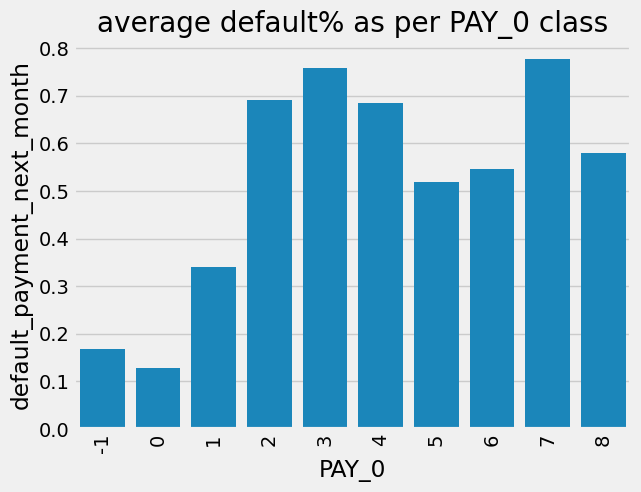

In [ ]:
sns.barplot(x="PAY_0",y="default_payment_next_month",data=data,ci=None)
plt.xticks(rotation=90)
plt.title('average default% as per PAY_0 class')


After preprocessing: After combining Categories -2 and 0, Category 7 has the highest observed default rate among the repayment-status categories.

AGE-> Continuous

In [ ]:
print('Oldest Passenger was of:',data['AGE'].max(),'Years')
print('Youngest Passenger was of:',data['AGE'].min(),'Years')
print('Average Age on the ship:',data['AGE'].mean(),'Years')

Oldest Passenger was of: 79 Years
Youngest Passenger was of: 21 Years
Average Age on the ship: 35.47972070025391 Years


<Axes: xlabel='default_payment_next_month', ylabel='AGE'>

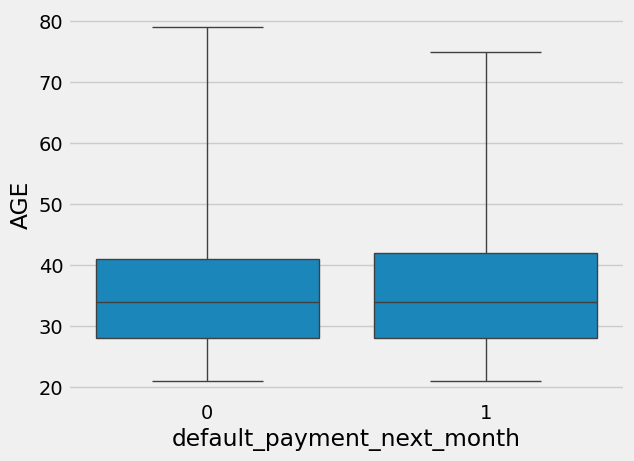

In [ ]:
sns.boxplot(y="AGE",x = "default_payment_next_month",whis=3, data = data)

The age distributions of defaulters and non-defaulters are very similar, with nearly identical medians and interquartile ranges, suggesting limited separation between the two groups. I retain it in the baseline model and will evaluate its contribution during model evaluation by comparing model performance with and without the feature.

LIMIT_BAL -> CONTINIOUS

In [ ]:
print('Maximum Limit Balance was:',data['LIMIT_BAL'].max())
print('Minimum Limit Balance was:',data['LIMIT_BAL'].min())
print('Average Limit Balance was:',data['LIMIT_BAL'].mean())


Maximum Limit Balance was: 1000000.0
Minimum Limit Balance was: 10000.0
Average Limit Balance was: 167523.37565147667


<Axes: xlabel='default_payment_next_month', ylabel='LIMIT_BAL'>

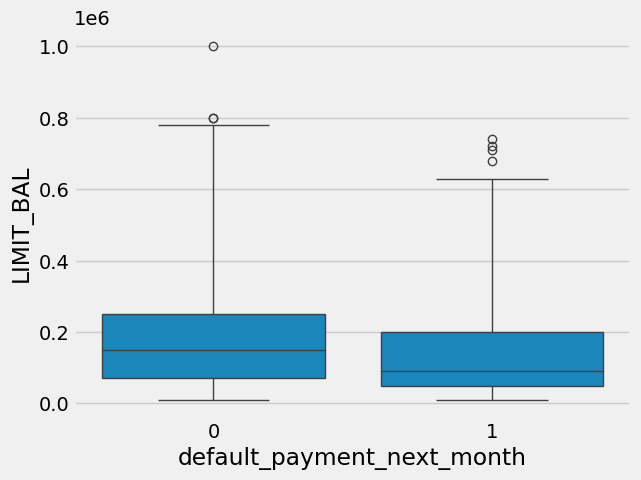

In [ ]:
sns.boxplot(y="LIMIT_BAL", x= "default_payment_next_month",whis=3, data = data)


Customers who defaulted tend to have lower credit limits than those who didn't.

BILL_AMT(s)-> CONTINUOUS

BILL_AMT1

In [ ]:
print('Maximum at Bill Amount 1 is:',data['BILL_AMT1'].max())
print('Minimum at Bill Amount 1 is:',data['BILL_AMT1'].min())
print('Average at Bill Amount 1 is:',data['BILL_AMT1'].mean())


Maximum at Bill Amount 1 is: 964511.0
Minimum at Bill Amount 1 is: -165580.0
Average at Bill Amount 1 is: 51297.38610851263


<Axes: xlabel='default_payment_next_month', ylabel='BILL_AMT1'>

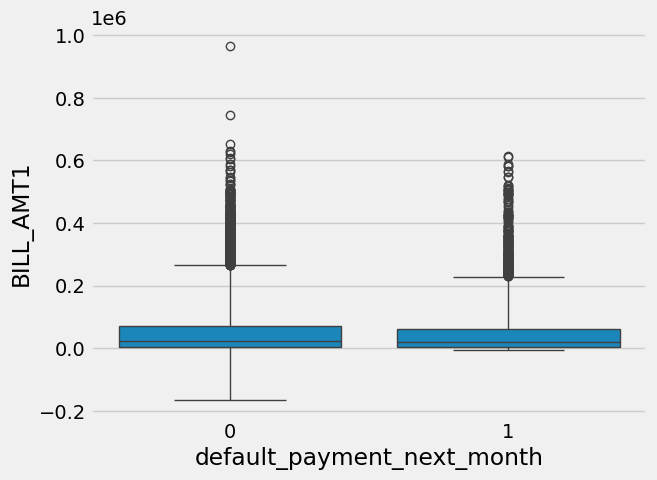

In [ ]:
sns.boxplot(y="BILL_AMT1", x= "default_payment_next_month",whis=3, data = data)


BILL_AMT1 shows substantial overlap between defaulters and non-defaulters, with limited separation between the two groups. I retain it in the baseline model and will evaluate its contribution during model evaluation by comparing model performance with and without the feature.

PAY_AMT1-> CONTINOUS

In [ ]:
print('Maximum at Bill Amount 1 is:',data['PAY_AMT1'].max())
print('Minimum at Bill Amount 1 is:',data['PAY_AMT1'].min())
print('Average at Bill Amount 1 is:',data['PAY_AMT1'].mean())


Maximum at Bill Amount 1 is: 873552.0
Minimum at Bill Amount 1 is: 0.0
Average at Bill Amount 1 is: 5659.603033542697


<Axes: xlabel='default_payment_next_month', ylabel='PAY_AMT1'>

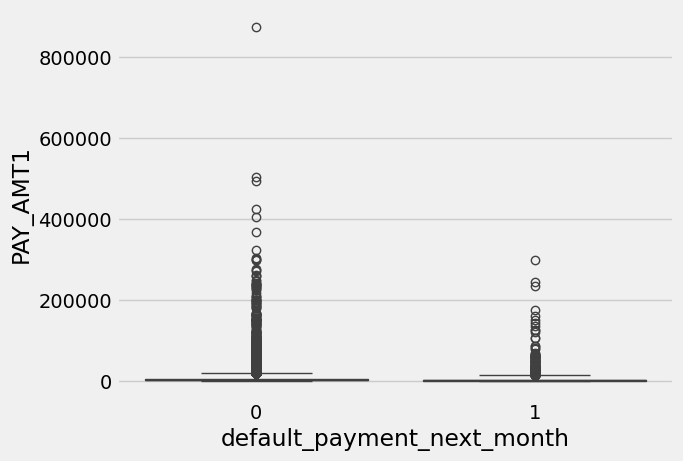

In [ ]:
sns.boxplot(y="PAY_AMT1", x= "default_payment_next_month",whis=3, data = data)


There is substantial overlap in PAY_AMT1 between defaulters and non-defaulters, with no clear separation between the two groups based on the central distribution.

In [ ]:
keep_cols = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
             'PAY_0', 'BILL_AMT1', 'PAY_AMT1', 'default_payment_next_month']

data2 = data[keep_cols].copy()

For now not considering PAY_2 - PAY_6, BILL_AMT2 - BILL_AMT6 and PAY_AMT2 - PAY_AMT6

# Models

In [ ]:
# train-test split with stratification

from sklearn.model_selection import train_test_split

X = data2.drop('default_payment_next_month', axis=1)
y = data2['default_payment_next_month']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

In [ ]:
X_train.shape      # rows and columns

(20952, 8)

In [ ]:
X_test.shape

(8980, 8)

In [ ]:
# Importing relevant libraries for modeling
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


In [ ]:
# Creating prepocessor
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
ordinal_cols = ['PAY_0']          # left untouched
num_cols = [c for c in X_train.columns if c not in cat_cols + ordinal_cols]

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('ord', 'passthrough', ordinal_cols),
    ('num', StandardScaler(), num_cols)
])

### Models Used

- **Logistic Regression:** Used as an interpretable baseline model for binary classification.
- **Linear SVM:** Included as a linear classification model for comparison with Logistic Regression.
- **RBF SVM:** Included to assess whether a nonlinear decision boundary could improve predictive performance.

The models were compared using cross-validation and classification metrics, including Accuracy, ROC-AUC, precision, recall, and F1-score.

In [ ]:
# Pipelines for three models, each sharing the same preprocessor and using class_weight='balanced' to handle class imbalance:
# logistic regression, linear-kernel SVC, and RBF-kernel SVC

logistic_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])

linear_svc_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', SVC(kernel='linear', class_weight='balanced', probability=False))
])

rbf_svc_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', SVC(kernel='rbf', class_weight='balanced', probability=False))
])


In [ ]:
# 5-fold cross-validation of the three pipelines on the training set,
# reporting mean accuracy, precision, recall, F1 and ROC-AUC

from sklearn.model_selection import cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score ,f1_score, roc_auc_score

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

models = {
    'Logistic Regression': logistic_pipeline,
    'Linear SVC': linear_svc_pipeline,
    'RBF SVC': rbf_svc_pipeline
}

for name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    print(name)
    print("Accuracy:", results['test_accuracy'].mean())
    print("Precision:", results['test_precision'].mean())
    print("Recall:", results['test_recall'].mean())
    print("F1:", results['test_f1'].mean())
    print("ROC-AUC:", results['test_roc_auc'].mean())
    print()

Logistic Regression
Accuracy: 0.7271373992115164
Precision: 0.4198288118858873
Recall: 0.6014717345310123
F1: 0.49421139791338
ROC-AUC: 0.7229755145497447

Linear SVC
Accuracy: 0.7836006011290246
Precision: 0.511469693549804
Recall: 0.5262886956683122
F1: 0.5185501542926888
ROC-AUC: 0.7188484572861159

RBF SVC
Accuracy: 0.7778732925253512
Precision: 0.4988398992163899
Recall: 0.5398583942689581
F1: 0.5184738357493444
ROC-AUC: 0.7537577064888666



Interpretation: Linear SVC has the highest accuracy, but accuracy alone is misleading on imbalanced data, and it is nearly identical for the two SVCs. All three models show only moderate precision, recall and F1 (around 0.5 for the SVCs). Logistic Regression has the best recall but the lowest precision. RBF SVC has the highest ROC-AUC (0.754), which suggests the best class separation, while its F1 is equal to Linear SVC's. I will select RBF SVC as the baseline model for further improvement.